<a href="https://colab.research.google.com/github/pjacierda/busa3022-market-intelligence/blob/main/BUSA3022_starter_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Really Big Bank – Market Intelligence Pipeline (Starter Notebook)
**BUSA3022 Analytics Lead Case Study – group baseline**

This notebook is the shared Phase 1 foundation. It:
1. Ingests **S&P 500** daily data from Yahoo Finance (`^GSPC`)
2. Ingests **VIX** daily data from FRED (`VIXCLS`)
3. Saves untouched copies to the **raw** layer (storage kept separate from transformation)
4. Validates both sources and logs every data quality issue to `logs/dq_log.csv` – nothing is silently dropped
5. Aligns both sources on a common date axis and writes one clean file that follows the agreed **data contract**

**How to use:** Runtime → Run all. Then File → Save a copy in GitHub to commit it to the group repo.

> ⚠️ This notebook was generated with AI assistance (Claude, Anthropic). Review every cell before relying on it, and record anything you had to fix in `docs/ai_log.md`.

## 1. Setup

In [1]:
!pip install yfinance -q

In [2]:
import os, time, io
from datetime import datetime, timedelta, timezone

import pandas as pd
import requests
import yfinance as yf

# ---- Configuration (change here, not inside functions) ----
SP500_TICKER  = "^GSPC"
FRED_SERIES   = "VIXCLS"
LOOKBACK_DAYS = 365          # 1 year: covers the 90-day dashboard plus warm-up for rolling metrics
END_DATE      = datetime.now(timezone.utc).date()
START_DATE    = END_DATE - timedelta(days=LOOKBACK_DAYS)
RUN_ID        = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

# ---- Layered storage: raw (as received) -> clean (transformed) -> logs ----
for folder in ["data/raw", "data/clean", "logs"]:
    os.makedirs(folder, exist_ok=True)

print(f"Run {RUN_ID}: {START_DATE} to {END_DATE}")

Run 20261021T000931Z: 2025-10-21 to 2026-10-21


## 2. Data quality logging
Every check writes a row to `logs/dq_log.csv`, whether it passes or fails. This is the audit trail that proves bad records are never silently dropped.

In [3]:
DQ_LOG_PATH = "logs/dq_log.csv"

def log_dq(source, check, status, detail="", records_affected=0):
    """Append one data quality event. status = PASS / WARN / FAIL."""
    row = pd.DataFrame([{
        "run_id": RUN_ID,
        "logged_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "source": source,
        "check": check,
        "status": status,
        "records_affected": records_affected,
        "detail": detail,
    }])
    row.to_csv(DQ_LOG_PATH, mode="a", header=not os.path.exists(DQ_LOG_PATH), index=False)
    print(f"[{status}] {source} | {check} | {detail}")

## 3. Failure handling: retry with backoff
Wraps any download. If the API times out or errors, it waits and retries (2s, 4s, ...). Every failed attempt is logged; if all attempts fail, the run stops loudly rather than continuing with missing data.

In [4]:
def with_retry(fn, source, attempts=3, base_wait=2):
    for attempt in range(1, attempts + 1):
        try:
            return fn()
        except Exception as e:
            log_dq(source, "download_attempt", "WARN", f"attempt {attempt} failed: {e}")
            if attempt == attempts:
                log_dq(source, "download", "FAIL", f"gave up after {attempts} attempts")
                raise
            time.sleep(base_wait ** attempt)

## 4. Ingest: S&P 500 (Yahoo Finance)

In [5]:
def fetch_sp500():
    df = yf.download(SP500_TICKER, start=START_DATE, end=END_DATE + timedelta(days=1),
                     interval="1d", auto_adjust=False, progress=False)
    if df is None or df.empty:
        raise ValueError("Yahoo returned no rows")
    # Newer yfinance versions return two-level column headers even for one ticker
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df.reset_index()
    return df

sp500_raw = with_retry(fetch_sp500, "yahoo_sp500")
sp500_raw.to_csv(f"data/raw/sp500_{RUN_ID}.csv", index=False)
log_dq("yahoo_sp500", "download", "PASS", f"{len(sp500_raw)} rows saved to raw layer", len(sp500_raw))
sp500_raw.tail()

[PASS] yahoo_sp500 | download | 251 rows saved to raw layer


Price,Date,Adj Close,Close,High,Low,Open,Volume
246,2026-10-14,7718.939941,7718.939941,7789.149902,7693.310059,7774.180176,5955580000
247,2026-10-15,7744.060059,7744.060059,7754.149902,7669.660156,7687.310059,6055670000
248,2026-10-16,7659.439941,7659.439941,7756.839844,7631.770020,7745.319824,5482060000
249,2026-10-19,7690.729980,7690.729980,7731.180176,7684.790039,7702.770020,4587260000
250,2026-10-20,7712.569824,7712.569824,7748.419922,7668.029785,7679.009766,2721619000


## 5. Ingest: VIX (FRED)
Uses the FRED API if a key is stored in Colab **Secrets** (key icon in the left sidebar, name it `FRED_API_KEY`). Otherwise it falls back to FRED's public CSV download, so the notebook still runs for everyone. Never paste the key into a cell.

In [6]:
def get_fred_key():
    try:
        from google.colab import userdata
        return userdata.get("FRED_API_KEY")
    except Exception:
        return os.environ.get("FRED_API_KEY")

def fetch_vix():
    key = get_fred_key()
    if key:
        r = requests.get("https://api.stlouisfed.org/fred/series/observations", timeout=30, params={
            "series_id": FRED_SERIES, "api_key": key, "file_type": "json",
            "observation_start": str(START_DATE), "observation_end": str(END_DATE)})
        r.raise_for_status()
        df = pd.DataFrame(r.json()["observations"])[["date", "value"]]
        df.columns = ["date", FRED_SERIES]
    else:
        r = requests.get("https://fred.stlouisfed.org/graph/fredgraph.csv", timeout=30,
                         params={"id": FRED_SERIES, "cosd": str(START_DATE), "coed": str(END_DATE)})
        r.raise_for_status()
        df = pd.read_csv(io.StringIO(r.text))
    if df.empty:
        raise ValueError("FRED returned no rows")
    return df

vix_raw = with_retry(fetch_vix, "fred_vix")
vix_raw.to_csv(f"data/raw/vix_{RUN_ID}.csv", index=False)
log_dq("fred_vix", "download", "PASS", f"{len(vix_raw)} rows saved to raw layer", len(vix_raw))
vix_raw.tail()

[PASS] fred_vix | download | 260 rows saved to raw layer


,observation_date,VIXCLS
255,2026-10-13,15.27
256,2026-10-14,16.87
257,2026-10-15,16.46
258,2026-10-16,19.99
259,2026-10-19,18.44


## 6. Validate: schema checks
If a provider renames or drops a column (a **schema change**), the run fails loudly here instead of producing a quietly broken dataset.

In [7]:
def standardise_sp500(df):
    df = df.copy()
    date_col = next((c for c in df.columns if str(c).lower() in ("date", "datetime")), None)
    required = {"Close", "Volume"}
    missing = required - set(df.columns)
    if date_col is None or missing:
        log_dq("yahoo_sp500", "schema", "FAIL", f"date column found: {date_col}; missing: {missing}")
        raise KeyError("S&P 500 schema changed – check the raw file")
    log_dq("yahoo_sp500", "schema", "PASS", "Date, Close, Volume present")
    out = pd.DataFrame({
        # Yahoo daily bars are already the US/Eastern trading date; strip any time/zone part
        "date": pd.to_datetime(df[date_col]).dt.tz_localize(None).dt.normalize(),
        "sp500_close": pd.to_numeric(df["Close"], errors="coerce"),
        "sp500_volume": pd.to_numeric(df["Volume"], errors="coerce"),
    })
    return out

def standardise_vix(df):
    df = df.copy()
    date_col = next((c for c in df.columns if str(c).lower() in ("date", "observation_date")), None)
    if date_col is None or FRED_SERIES not in df.columns:
        log_dq("fred_vix", "schema", "FAIL", f"columns received: {list(df.columns)}")
        raise KeyError("VIX schema changed – check the raw file")
    log_dq("fred_vix", "schema", "PASS", f"{date_col}, {FRED_SERIES} present")
    out = pd.DataFrame({
        # FRED dates are plain calendar dates (US/Eastern market close)
        "date": pd.to_datetime(df[date_col]).dt.normalize(),
        # FRED marks missing days with "." or a blank – coerce both to NaN so they can be counted
        "vix_close": pd.to_numeric(df[FRED_SERIES], errors="coerce"),
    })
    return out

sp500 = standardise_sp500(sp500_raw)
vix = standardise_vix(vix_raw)

[PASS] yahoo_sp500 | schema | Date, Close, Volume present
[PASS] fred_vix | schema | observation_date, VIXCLS present


## 7. Validate: record-level quality checks

In [8]:
def quality_checks(df, source, value_cols):
    dups = df["date"].duplicated().sum()
    log_dq(source, "duplicate_dates", "WARN" if dups else "PASS", f"{dups} duplicate dates", dups)
    for col in value_cols:
        nulls = df[col].isna().sum()
        log_dq(source, f"null_{col}", "WARN" if nulls else "PASS", f"{nulls} missing values", nulls)
        bad = (df[col] <= 0).sum()
        log_dq(source, f"non_positive_{col}", "WARN" if bad else "PASS", f"{bad} values <= 0", bad)
    return df.drop_duplicates("date", keep="last")

sp500 = quality_checks(sp500, "yahoo_sp500", ["sp500_close", "sp500_volume"])
vix = quality_checks(vix, "fred_vix", ["vix_close"])

[PASS] yahoo_sp500 | duplicate_dates | 0 duplicate dates
[PASS] yahoo_sp500 | null_sp500_close | 0 missing values
[PASS] yahoo_sp500 | non_positive_sp500_close | 0 values <= 0
[PASS] yahoo_sp500 | null_sp500_volume | 0 missing values
[PASS] yahoo_sp500 | non_positive_sp500_volume | 0 values <= 0
[PASS] fred_vix | duplicate_dates | 0 duplicate dates
[WARN] fred_vix | null_vix_close | 3 missing values
[PASS] fred_vix | non_positive_vix_close | 0 values <= 0


## 8. Align on a common date axis
- **Time zones:** both sources are US-listed and dated by the US/Eastern trading day, so dates are compared as plain calendar dates with no time component.
- **Join rule:** the S&P 500 trading calendar is the master axis (a left join), because the dashboard is about market activity on trading days.
- **VIX rows with no S&P session** (mostly US holidays where FRED leaves a blank) are excluded from the merge, but counted and logged first.
- **S&P days with no VIX value** are forward-filled from the previous VIX close and flagged with `vix_missing = True`, so the dashboard can show them differently.

In [9]:
sp_dates = set(sp500["date"])
vix_only = vix[~vix["date"].isin(sp_dates)]
if len(vix_only):
    blank = vix_only["vix_close"].isna().sum()
    log_dq("merge", "vix_dates_without_sp500_session", "WARN",
           f"{len(vix_only)} VIX dates excluded (no S&P trading that day); {blank} of them were blank holidays",
           len(vix_only))

merged = sp500.merge(vix, on="date", how="left").sort_values("date").reset_index(drop=True)
merged["vix_missing"] = merged["vix_close"].isna()
n_missing = int(merged["vix_missing"].sum())
merged["vix_close"] = merged["vix_close"].ffill()
log_dq("merge", "vix_forward_fill", "WARN" if n_missing else "PASS",
       f"{n_missing} S&P trading days had no VIX value; forward-filled and flagged", n_missing)

for _, r in merged[merged["vix_missing"]].iterrows():
    log_dq("merge", "vix_filled_date", "WARN", f"{r['date'].date()} filled with previous VIX close", 1)

[WARN] merge | vix_dates_without_sp500_session | 10 VIX dates excluded (no S&P trading that day); 3 of them were blank holidays
[WARN] merge | vix_forward_fill | 1 S&P trading days had no VIX value; forward-filled and flagged
[WARN] merge | vix_filled_date | 2026-10-20 filled with previous VIX close


## 9. Apply the data contract and save the clean layer
Everyone builds on `data/clean/market_daily.csv`. **Do not change these columns without agreeing as a group.**

| Column | Type | Meaning |
|---|---|---|
| `date` | date (YYYY-MM-DD) | US/Eastern trading date |
| `sp500_close` | float | S&P 500 closing price |
| `sp500_volume` | integer | S&P 500 daily volume |
| `vix_close` | float | VIX closing value (forward-filled where missing) |
| `vix_missing` | bool | True if the VIX value was filled rather than reported |

In [10]:
CONTRACT = ["date", "sp500_close", "sp500_volume", "vix_close", "vix_missing"]

clean = merged[CONTRACT].copy()
clean["date"] = clean["date"].dt.strftime("%Y-%m-%d")

assert list(clean.columns) == CONTRACT, "Column order does not match the data contract"
assert clean["date"].is_unique, "Duplicate dates in clean output"

clean.to_csv("data/clean/market_daily.csv", index=False)
log_dq("clean", "contract_output", "PASS", f"{len(clean)} rows written to data/clean/market_daily.csv", len(clean))
clean.tail(10)

[PASS] clean | contract_output | 251 rows written to data/clean/market_daily.csv


,date,sp500_close,sp500_volume,vix_close,vix_missing
241,2026-10-07,7801.770020,5111150000,15.08,False
242,2026-10-08,7765.359863,6082070000,15.41,False
243,2026-10-09,7811.540039,4782640000,14.84,False
244,2026-10-12,7807.240234,4148500000,15.21,False
245,2026-10-13,7805.450195,4869340000,15.27,False
246,2026-10-14,7718.939941,5955580000,16.87,False
247,2026-10-15,7744.060059,6055670000,16.46,False
248,2026-10-16,7659.439941,5482060000,19.99,False
249,2026-10-19,7690.729980,4587260000,18.44,False
250,2026-10-20,7712.569824,2721619000,18.44,True


## 10. Sanity check (not the dashboard)

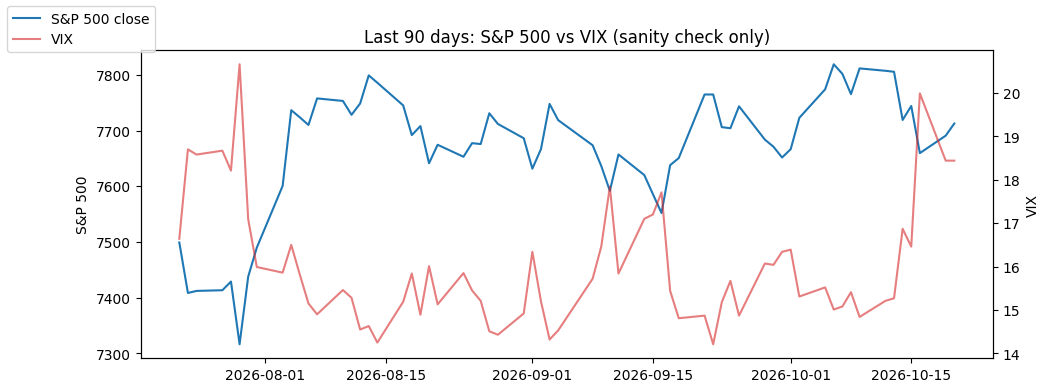

     source                           check status                                                                         detail
yahoo_sp500                        download   PASS                                                    251 rows saved to raw layer
   fred_vix                        download   PASS                                                    260 rows saved to raw layer
yahoo_sp500                          schema   PASS                                                    Date, Close, Volume present
   fred_vix                          schema   PASS                                               observation_date, VIXCLS present
yahoo_sp500                 duplicate_dates   PASS                                                              0 duplicate dates
yahoo_sp500                null_sp500_close   PASS                                                               0 missing values
yahoo_sp500        non_positive_sp500_close   PASS                                        

In [11]:
import matplotlib.pyplot as plt

last90 = merged[merged["date"] >= merged["date"].max() - pd.Timedelta(days=90)]
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(last90["date"], last90["sp500_close"], label="S&P 500 close")
ax1.set_ylabel("S&P 500")
ax2 = ax1.twinx()
ax2.plot(last90["date"], last90["vix_close"], color="tab:red", alpha=0.6, label="VIX")
ax2.set_ylabel("VIX")
ax1.set_title("Last 90 days: S&P 500 vs VIX (sanity check only)")
fig.legend(loc="upper left")
plt.show()

print(pd.read_csv(DQ_LOG_PATH).query("run_id == @RUN_ID")[["source", "check", "status", "detail"]].to_string(index=False))

## Next steps by role
- **Pipeline lead:** schedule this (e.g. a GitHub Action or a timed Colab run), and demo the failure handling by temporarily renaming a column or setting `SP500_TICKER` to a bad value.
- **Curation lead:** commit the plain-language metric definitions to `docs/` *first*, then build the metrics in a new notebook that reads `data/clean/market_daily.csv`.
- **Dashboard lead:** build the 90-day charts and the VIX RAG signal (Green < 20, Amber 20–30, Red > 30) from the same clean file.
- **Everyone:** log any AI mistakes you find in this or later notebooks in `docs/ai_log.md`.